<a href="https://colab.research.google.com/github/sihCY/Hospital_Simulation_LangChainAI_Multi-Agents/blob/main/HospitalSimulationLangChainAIMulti_AgentsV4withRAG.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Setup

## Install Libraries

In [ ]:
#!uv pip install --upgrade --system pip

In [1]:
!pip install langchain langgraph langchain-groq langchain_community gradio requests transformers torch chromadb datasets duckduckgo-search fastembed onnxruntime python-dotenv

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 43.0 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.0/1.0 MB 41.1 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 23.3/23.3 MB 100.9 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 23.8/23.8 MB 90.0 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.5/7.5 MB 111.6 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.6/6.6 MB 63.3 MB/s  0:00:00
  Attempting uninstall: urllib3
    Found existing installation: urllib3 2.5.0
    Uninstalling urllib3-2.5.0:
      Successfully uninstalled urllib3-2.5.0
  Attempting uninstall: opentelemetry-api
    Found existing installation: opentelemetry-api 1.42.1
    Uninstalling opentelemetry-api-1.42.1:
      Successfully uninstalled opentelemetry-api-1.42.1
  Attempting uninstall: requests
    Found existing installation: requests 2.32.4
    Uninstalling requests-2.32.4:
      Successfully uninstalled requests-2.32.4
  Attempting uninstall: opentele

In [2]:
pip install --upgrade datasets

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 604.4/604.4 kB 9.7 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 53.9/53.9 MB 39.6 MB/s  0:00:01
  Attempting uninstall: pyarrow
    Found existing installation: pyarrow 23.0.1
    Uninstalling pyarrow-23.0.1:
      Successfully uninstalled pyarrow-23.0.1
  Attempting uninstall: datasets
    Found existing installation: datasets 4.8.5
    Uninstalling datasets-4.8.5:
      Successfully uninstalled datasets-4.8.5
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [datasets]


## Load Libraries

In [3]:
# General
import os
import kagglehub
import pandas as pd
import json
from typing import Literal
from datasets import load_dataset
import random

# Environmental variables
from dotenv import load_dotenv

# Markdown
from IPython.display import Markdown, display, Image as IPImage

# Image
from PIL import Image

# langchain for llms
from langchain_groq import ChatGroq

# Langchain Core
from langchain_core.prompts import PromptTemplate, ChatPromptTemplate
from langchain_core.output_parsers import JsonOutputParser, StrOutputParser
from langchain_core.messages import HumanMessage
from langchain_core.documents import Document
from langchain_core.runnables import RunnablePassthrough
from langchain_core.tools import tool

# LangChain Community
from langchain_community.vectorstores import Chroma
from langchain_community.embeddings import HuggingFaceEmbeddings

# LangGraph
from langgraph.checkpoint.memory import MemorySaver
from langgraph.graph import END, START, StateGraph, MessagesState
from langgraph.prebuilt import ToolNode

# Hugging Face
from transformers import AutoModelForImageClassification, AutoProcessor

# Pydantic
from pydantic import BaseModel, Field, model_validator

# Text splitting
from langchain_text_splitters import RecursiveCharacterTextSplitter

# Multi-query retriever - UPDATED
from langchain_classic.retrievers.multi_query import MultiQueryRetriever

# Legacy output parsers
from langchain_classic.output_parsers import StructuredOutputParser, ResponseSchema

/tmp/ipykernel_1933/3737070606.py:31: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.vectorstores import Chroma


## APIs

In [5]:
# Set the SERPER_API_KEY as an environment variable
load_dotenv('/content/MyAPIKeys.env')

os.environ["SERPER_API_KEY"] = os.getenv("SERPER_API_KEY")
os.environ["GROQ_API_KEY"] = os.getenv("GROQ_API_KEY")
os.environ["HF_TOKEN"] = os.getenv("HF_TOKEN")

GROQ_API_KEY = os.environ["GROQ_API_KEY"]
HF_TOKEN = os.environ["HF_TOKEN"]

## Test Hugging Face Token

In [ ]:
# Test HF_TOKEN Only
# Quick check for your working token

import os
from huggingface_hub import HfApi
from datasets import load_dataset

print("🔍 Testing HF_TOKEN...")

# Check HF_TOKEN
hf_token = os.getenv("HF_TOKEN")

if hf_token:
    print(f"✅ HF_TOKEN present: {len(hf_token)} characters")
    print(f"Token starts with: {hf_token[:10]}...")

    # Test API connectivity
    try:
        api = HfApi(token=hf_token)
        user_info = api.whoami()
        print(f"✅ Authenticated as: {user_info['name']}")

        # Test dataset access
        print("Testing dataset access...")
        test_ds = load_dataset("squad", split="train[:1]", token=hf_token)
        print("✅ Can access public datasets")

        print("✅ HF_TOKEN is working perfectly!")

    except Exception as e:
        print(f"❌ HF_TOKEN failed: {str(e)[:100]}...")
else:
    print("❌ HF_TOKEN not found")


🔍 Testing HF_TOKEN...
✅ HF_TOKEN present: 37 characters
Token starts with: hf_VCPbrEY...
✅ Authenticated as: SihemO
Testing dataset access...


README.md:   0%|          | 0.00/7.62k [00:00<?, ?B/s]

❌ HF_TOKEN failed: Invalid HF URI 'hf://datasets/squad@7b6d24c440a36b6815f21b70d25016731768db1f/.huggingface.yaml'. Rep...


In [ ]:

import os
import traceback
import datasets
import huggingface_hub
from huggingface_hub import HfApi
from datasets import load_dataset

print("datasets:", datasets.__version__)
print("huggingface_hub:", huggingface_hub.__version__)

hf_token = os.getenv("HF_TOKEN")

if not hf_token:
    raise RuntimeError("HF_TOKEN is missing")

# 1. Test authentication
try:
    user_info = HfApi(token=hf_token).whoami()
    print(f"✅ Authenticated as: {user_info['name']}")
except Exception:
    print("❌ Authentication failed")
    traceback.print_exc()
    raise

# 2. Test dataset loading independently
try:
    print("Testing SQuAD dataset...")
    test_ds = load_dataset(
        "rajpurkar/squad",
        split="train[:1]",
        token=hf_token,
    )
    print("✅ Dataset loaded successfully")
    print(test_ds[0])
except Exception:
    print("❌ Dataset loading failed:")
    traceback.print_exc()


datasets: 5.1.0
huggingface_hub: 1.33.0
✅ Authenticated as: SihemO
Testing SQuAD dataset...


README.md:   0%|          | 0.00/7.62k [00:00<?, ?B/s]

plain_text/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 14.5MB            

plain_text/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/validation-00000-of-00001.par(…): reconstructing file:   0%|          |  0.00B / 1.82MB            

plain_text/validation-00000-of-00001.par(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/87599 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/10570 [00:00<?, ? examples/s]

✅ Dataset loaded successfully
{'id': '5733be284776f41900661182', 'title': 'University_of_Notre_Dame', 'context': 'Architecturally, the school has a Catholic character. Atop the Main Building\'s gold dome is a golden statue of the Virgin Mary. Immediately in front of the Main Building and facing it, is a copper statue of Christ with arms upraised with the legend "Venite Ad Me Omnes". Next to the Main Building is the Basilica of the Sacred Heart. Immediately behind the basilica is the Grotto, a Marian place of prayer and reflection. It is a replica of the grotto at Lourdes, France where the Virgin Mary reputedly appeared to Saint Bernadette Soubirous in 1858. At the end of the main drive (and in a direct line that connects through 3 statues and the Gold Dome), is a simple, modern stone statue of Mary.', 'question': 'To whom did the Virgin Mary allegedly appear in 1858 in Lourdes France?', 'answers': {'text': ['Saint Bernadette Soubirous'], 'answer_start': [515]}}


## Setup LLM (Llama 3.3 via Groq)

In [6]:
os.environ["GROQ_API_KEY"] = GROQ_API_KEY

model_qwen3_8="qwen/qwen3.8-27b"
model_3_3 ='llama-3.3-70b-versatile' # Very Large and Versatile Model with 70 Billion parameters
model_4_scout ='meta-llama/llama-4-scout-17b-16e-instruct' # Llama 4 Scout is Meta's natively multimodal model, 17 billion parameter mixture-of-experts architecture (16 experts),

llm = ChatGroq(
    model= model_qwen3_8, #
    temperature=0,
    max_tokens=None,
    timeout=None,
    max_retries=2,
   # groq_api_key=os.getenv("GROQ_API_KEY")
    # other params...
)

# A test message
# new text:
response = llm.invoke("hi, Please generate 10 unique Dutch names for both male and female?")
response

AIMessage(content='Here are 10 unique Dutch names, split into 5 male and 5 female options. These names are authentic to the Netherlands and Belgium, ranging from traditional to modern, with brief meanings or notes for context:\n\n### Male Names\n1. **Joris** – A classic Dutch name, derived from the Greek *Georgios* (farmer/earth-worker). Very popular and timeless.\n2. **Thijs** – A traditional Dutch name, often associated with strength and resilience. It’s a diminutive of *Dietrich* or *Theodoric*.\n3. **Lars** – Common in the Netherlands (especially in the north), derived from the Norse *Lars* (crown). Simple and strong.\n4. **Finn** – Modern and trendy in the Netherlands, meaning “fair” or “fair-haired.” It has a fresh, contemporary feel.\n5. **Bram** – A short, friendly name derived from *Abraham*. It’s widely used and feels approachable yet distinctive.\n\n### Female Names\n1. **Lotte** – A beloved Dutch name, often a diminutive of *Charlotte* or *Lodewijk*. It’s cheerful, classic,

In [7]:
display(Markdown(response.content))

Here are 10 unique Dutch names, split into 5 male and 5 female options. These names are authentic to the Netherlands and Belgium, ranging from traditional to modern, with brief meanings or notes for context:

### Male Names
1. **Joris** – A classic Dutch name, derived from the Greek *Georgios* (farmer/earth-worker). Very popular and timeless.
2. **Thijs** – A traditional Dutch name, often associated with strength and resilience. It’s a diminutive of *Dietrich* or *Theodoric*.
3. **Lars** – Common in the Netherlands (especially in the north), derived from the Norse *Lars* (crown). Simple and strong.
4. **Finn** – Modern and trendy in the Netherlands, meaning “fair” or “fair-haired.” It has a fresh, contemporary feel.
5. **Bram** – A short, friendly name derived from *Abraham*. It’s widely used and feels approachable yet distinctive.

### Female Names
1. **Lotte** – A beloved Dutch name, often a diminutive of *Charlotte* or *Lodewijk*. It’s cheerful, classic, and very common.
2. **Sanne** – A traditional Dutch name, derived from *Sanne* (a form of *Sanna* or *Sanne*), meaning “grace” or “beauty.” Soft and elegant.
3. **Noor** – Meaning “light” or “radiance.” While of Arabic origin, it has become very popular and naturalized in the Netherlands in recent decades.
4. **Eva** – A timeless name meaning “life.” It’s simple, international, and consistently popular in Dutch-speaking countries.
5. **Mila** – A modern favorite, meaning “gracious” or “dear.” It’s short, sweet, and has gained significant popularity in the Netherlands since the 2010s.

Let me know if you’d like more options, specific styles (e.g., vintage, modern, nature-inspired), or names with particular meanings!

# First Agent: Chatbot Agent

In [8]:
from typing import Annotated
from typing_extensions import TypedDict
from langgraph.graph import StateGraph, START, END
from langgraph.graph.message import add_messages


class ChatState(TypedDict):
    # Messages have the type "list". The `add_messages` function
    # in the annotation defines how this state key should be updated
    # (in this case, it appends messages to the list, rather than overwriting them)
    messages: Annotated[list, add_messages]


chat_graph = StateGraph(ChatState)

def chatbot_agent(state: ChatState):
    return {"messages": [llm.invoke(state["messages"])]}

# The first argument is the unique node name
# The second argument is the function or object that will be called whenever
# the node is used.
chat_graph.add_node("chatbot_agent", chatbot_agent)
chat_graph.add_edge(START, "chatbot_agent")
chat_graph.add_edge("chatbot_agent", END)

# Finally, we'll want to be able to run our graph. To do so, call "compile()"
# We basically now give our AI Agent
graph_app = chat_graph.compile()

# Persistent state to maintain conversation history
persistent_state = {"messages": []}  # Start with an empty message list

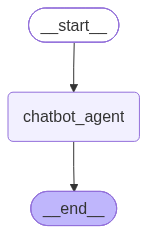

In [ ]:
from IPython.display import Image, display
display(Image(graph_app.get_graph(xray=True).draw_mermaid_png()))

In [ ]:
from typing import Annotated
from typing_extensions import TypedDict
from langgraph.graph import StateGraph, START, END
from langgraph.graph.message import add_messages
from IPython.display import display, Markdown

class ChatState(TypedDict):
    messages: Annotated[list, add_messages]

chat_graph = StateGraph(ChatState)

def chatbot_agent(state: ChatState):
    # Assuming `llm` is your language model that can handle the conversation history
    return {"messages": [llm.invoke(state["messages"])]}

chat_graph.add_node("chatbot_agent", chatbot_agent)
chat_graph.add_edge(START, "chatbot_agent")
chat_graph.add_edge("chatbot_agent", END)

graph_app = chat_graph.compile()

# Persistent state to maintain conversation history
persistent_state = {"messages": []}  # Start with an empty message list

def stream_graph_updates(user_input: str):
    global persistent_state
    # Append the user's message to the persistent state
    persistent_state["messages"].append(("user", user_input))

    is_finished = False
    for event in graph_app.stream(persistent_state):
        for value in event.values():
            last_msg = value["messages"][-1]
            display(Markdown("Assistant: " + last_msg.content))

            # Append the assistant's response to the persistent state
            persistent_state["messages"].append(("assistant", last_msg.content))

            finish_reason = last_msg.response_metadata.get("finish_reason")
            if finish_reason == "stop":
                is_finished = True
                break
        if is_finished:
            break

while True:
    try:
        user_input = input('User:')
        if user_input.lower() in ["quit", "exit", "q"]:
            print("Thank you and Goodbye!")
            break

        stream_graph_updates(user_input)
    except Exception as e:
        print(f"An error occurred: {e}")
        break

User:hi


Assistant: Hello! How can I help you today?

User:how's the weather today?


Assistant: I don't have access to your current location, so I can't tell you the exact weather conditions where you are.

However, if you let me know your **city** or **zip code**, I can look up the current weather forecast for you! Alternatively, you can check a local weather app or website for the most up-to-date information.

User:Evere 1140


Assistant: I don't have access to real-time data, so I can't provide the current weather conditions for Evere (1140), Belgium.

For the most accurate and up-to-date forecast, please check a reliable weather service such as:
*   **KMI (Royal Meteorological Institute of Belgium)**: [meteo.be](https://www.meteo.be)
*   **Weather.com**
*   **AccuWeather**
*   Your local news or weather app

Would you like help with anything else?

User:q
Thank you and Goodbye!


# Second Agent: Add Search to Chatbot to make it Stronger

In [9]:
from langchain_community.tools import GoogleSerperResults
from typing import List, Annotated
from langchain_core.messages import BaseMessage
from langgraph.prebuilt import ToolNode, create_react_agent
import operator
import functools

class ChatState(TypedDict):
    # Messages have the type "list". The `add_messages` function
    # in the annotation defines how this state key should be updated
    # (in this case, it appends messages to the list, rather than overwriting them)
    messages: Annotated[list, add_messages]

def agent_node(state, agent, name):
    result = agent.invoke(state)
    return {
        "messages": [HumanMessage(content=result["messages"][-1].content, name=name)]
    }


class SearchState(TypedDict):
    # A message is added after each team member finishes
    messages: Annotated[List[BaseMessage], operator.add]

# Search Tool

serper_tool = GoogleSerperResults(
    num_results=5,
    # how many Google results to return
)

search_agent = create_react_agent(llm, tools=[serper_tool])
search_node = functools.partial(agent_node,
                                agent=search_agent,
                                name="search_agent")


# The first argument is the unique node name
# The second argument is the function or object that will be called whenever
# the node is used.
search_graph = StateGraph(SearchState)
search_graph.add_node("search_agent", search_node)
search_graph.add_edge(START, "search_agent")
search_graph.add_edge("search_agent", END)

# Finally, we'll want to be able to run our graph. To do so, call "compile()"
# We basically now give our AI Agent
search_app = search_graph.compile()

/tmp/ipykernel_1933/515804471.py:32: LangGraphDeprecatedSinceV10: create_react_agent has been moved to `langchain.agents`. Please update your import to `from langchain.agents import create_agent`. Deprecated in LangGraph V1.0 to be removed in V2.0.
  search_agent = create_react_agent(llm, tools=[serper_tool])


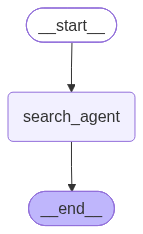

In [10]:
from IPython.display import Image, display
display(Image(search_app.get_graph(xray=True).draw_mermaid_png()))

In [11]:
from langchain_community.tools import GoogleSerperResults
from typing import List, Annotated
from langchain_core.messages import BaseMessage, HumanMessage
from langgraph.prebuilt import ToolNode, create_react_agent
from langgraph.graph import StateGraph, START, END
from langgraph.graph.message import add_messages
from IPython.display import display, Markdown
import operator
import functools

class ChatState(TypedDict):
    messages: Annotated[List[BaseMessage], operator.add]

def agent_node(state, agent, name):
    result = agent.invoke(state)
    return {
        "messages": [HumanMessage(content=result["messages"][-1].content, name=name)]
    }

class SearchState(TypedDict):
    messages: Annotated[List[BaseMessage], operator.add]

# Search Tool
serper_tool = GoogleSerperResults(num_results=5)  # how many Google results to return

search_agent = create_react_agent(llm, tools=[serper_tool])
search_node = functools.partial(agent_node, agent=search_agent, name="search_agent")

# Create the search graph
search_graph = StateGraph(SearchState)
search_graph.add_node("search_agent", search_node)
search_graph.add_edge(START, "search_agent")
search_graph.add_edge("search_agent", END)

# Compile the search graph
search_app = search_graph.compile()

# Persistent state to maintain conversation history
persistent_state = {"messages": []}  # Start with an empty message list

def stream_graph_updates(user_input: str):
    global persistent_state
    # Append the user's message to the persistent state
    persistent_state["messages"].append(HumanMessage(content=user_input))

    # Display "Searching the Web Now..." message
    display(Markdown("**Assistant:** Searching the Web Now..."))

    is_finished = False
    for event in search_app.stream(persistent_state):
        for value in event.values():
            last_msg = value["messages"][-1]
            display(Markdown("**Assistant:** " + last_msg.content))

            # Append the assistant's response to the persistent state
            persistent_state["messages"].append(last_msg)

            finish_reason = last_msg.response_metadata.get("finish_reason")
            if finish_reason == "stop":
                is_finished = True
                break
        if is_finished:
            break

while True:
    try:
        user_input = input('User:')
        if user_input.lower() in ["quit", "exit", "q"]:
            print("Thank you and Goodbye!")
            break

        stream_graph_updates(user_input)
    except Exception as e:
        print(f"An error occurred: {e}")
        break

/tmp/ipykernel_1933/1989519487.py:26: LangGraphDeprecatedSinceV10: create_react_agent has been moved to `langchain.agents`. Please update your import to `from langchain.agents import create_agent`. Deprecated in LangGraph V1.0 to be removed in V2.0.
  search_agent = create_react_agent(llm, tools=[serper_tool])


User:hi


**Assistant:** Searching the Web Now...

An error occurred: Error code: 429 - {'error': {'message': "Request too large for model `qwen/qwen3.8-27b` in organization `org_01m50mjfkvexsvnndqjr62dkxs` service tier `on_demand` on output tokens per minute (OTPM): Limit 1000, Requested 1212. The request's expected output tokens exceed the enforced limit; reduce max_tokens (or the request's expected output) and try again. Need more tokens? Upgrade to Dev Tier today at https://console.groq.com/settings/billing", 'type': 'tokens', 'code': 'rate_limit_exceeded'}}
